# Adapting KryptoNet-40 with LoRA

This notebook adapts KryptoNet-40 to Kryptonite-40-Adapt with low-rank adaptation (LoRA, implemented in `lora.py`). It chooses learning rates by a grid search on validation accuracy, compares LoRA with the mock paper's zero-shot and probe baselines, full fine-tuning and training from scratch, studies the rank, the adapted layers, the amount of data and the cost of one training step, and writes the hidden-set predictions to `../hiddenlabels/y_predicted_40_adapt.npy`.

Everything runs on a laptop CPU.

In [1]:
import copy
import os
import sys
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from codecarbon import OfflineEmissionsTracker
from sklearn.model_selection import train_test_split
from torch.utils.flop_counter import FlopCounterMode
sys.path.insert(0, os.path.abspath("../.."))  # kryptonet.py is at the repository root
from kryptonet import kryptonet, load_kryptonet
from lora import LoRALinear, add_lora, count_trainable

# 5 runs to reduce noise
SEEDS = (0, 1, 2, 3, 4)
# Default values taken from the linear probe and MLP probe experiments in 
# Kryptonite-3.0; Quinn and Luther et al.
EPOCHS, PATIENCE, BATCH = 300, 40, 128
TARGET = 0.90
# linear probe and MLP probe learning rates taken from Kryptonite-3.0; Quinn 
# and Luther et al. 
LR = {"probe": 1e-2, "mlp_probe": 1e-3}
# full fine-tuning, LoRA and training from scratch get their learning rates 
# from this grid, so results don't get skewed by inappropriate learning rates
LR_GRID = (1e-4, 3e-4, 1e-3, 3e-3, 1e-2)
# LoRA rank for every experiment except the rank sweep. Peft's default value.
DEFAULT_RANK = 8
# LoRA alpha, where the update B A is scaled by ALPHA / r. Fixed across ranks, 
# uses Peft's default value.
ALPHA = 8.0
FIG_DIR = "figures"

# Figure text must be no smaller than the 10pt body text once the figure is one 
# column (3.25 in) wide.
plt.rcParams.update({"font.size": 10, "axes.titlesize": 10, 
                     "axes.labelsize": 10, "legend.fontsize": 10,
                     "xtick.labelsize": 10, "ytick.labelsize": 10})


def save(fig, name):
    os.makedirs(FIG_DIR, exist_ok=True)
    fig.savefig(f"{FIG_DIR}/{name}.pdf", bbox_inches="tight")

## Data

The test split is the one used for Figure 3 of the mock paper (20%, `random_state=42`), so accuracies are directly comparable with it. Each training run takes its own validation set out of the remaining 3,200 rows for early stopping and model selection.

In [2]:
X = np.load("../../Datasets/kryptonite-40-adapt-X.npy")
y = np.load("../../Datasets/kryptonite-40-adapt-y.npy")
X_hidden = np.load("../../Datasets/hidden-kryptonite-40-adapt-X.npy")
X_pool, X_test, y_pool, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
base = load_kryptonet("../../kryptonet40.pt")
print(f"pool {X_pool.shape}, test {X_test.shape}, hidden {X_hidden.shape}")

pool (3200, 40), test (800, 40), hidden (10000, 40)


## The LoRA Layer

`LoRALinear` in `lora.py` turns a pretrained layer $h = Wx + b$ with $W \in \mathbb{R}^{d_\text{out} \times d_\text{in}}$ into $h = Wx + b + \frac{\alpha}{r} BAx$, where $W$ and $b$ are frozen and only $A \in \mathbb{R}^{r \times d_\text{in}}$ and $B \in \mathbb{R}^{d_\text{out} \times r}$ are trained. $B$ starts at zero, so before training the adapted network is exactly the pretrained one, which the check below confirms.

In [3]:
with torch.no_grad():
    assert torch.equal(add_lora(base, DEFAULT_RANK, ALPHA)(torch.from_numpy(X_test)), base(torch.from_numpy(X_test)))

print(f"full fine-tuning: {count_trainable(base):>7,} trainable parameters")
for r in (1, 2, 4, 8, 16, 32):
    print(f"LoRA r = {r:>2} on W1-W4: {count_trainable(add_lora(base, r, ALPHA)):>7,} trainable parameters")

full fine-tuning: 809,473 trainable parameters
LoRA r =  1 on W1-W4:   3,624 trainable parameters
LoRA r =  2 on W1-W4:   7,248 trainable parameters
LoRA r =  4 on W1-W4:  14,496 trainable parameters
LoRA r =  8 on W1-W4:  28,992 trainable parameters
LoRA r = 16 on W1-W4:  57,984 trainable parameters
LoRA r = 32 on W1-W4: 115,968 trainable parameters


## Training

`fit` trains whichever parameters have `requires_grad` set, using Adam with early stopping on validation accuracy, as in the mock paper's notebook. `run` repeats one condition over the seeds, optionally on a random subset of `n` labelled rows, and records validation accuracy (for model selection), test accuracy (for reporting), the number of trainable parameters, the training time and the CPU energy the run used (see Compute Used).

In [4]:
# CodeCarbon reads the CPU's own energy counters (RAPL, through the Windows Energy Meter Interface on
# Windows 11 or /sys/class/powercap on Linux) at the start and end of each run, as in ../ModelExperiments.
MEASURED = ("intel_rapl", "windows_emi", "intel_power_gadget")
tracker = OfflineEmissionsTracker(country_iso_code="GBR", tracking_mode="machine", save_to_file=False,
                                  log_level="error", allow_multiple_runs=True)


def cpu_mode():
    # How CodeCarbon reads the CPU: one of MEASURED, or the name of a fallback estimate.
    return next((getattr(h, "_mode", None) for h in tracker._hardware if type(h).__name__ == "CPU"), None)


def accuracy(net, X, y):
    net.eval()
    with torch.no_grad():
        return float(((net(torch.from_numpy(X)).squeeze(1) > 0).long().numpy() == y).mean())


def fit(net, X, y, lr, seed):
    # Adam on the trainable parameters with early stopping on a 20% validation 
    # split; restores the best weights.
    # Split follows that of the mock paper's, by shuffling the rows with 
    # torch.randperm and holding out the first fifth.
    # Reseed here so each method trains and validates on the same rows.
    torch.manual_seed(seed)
    perm = torch.randperm(len(y)).numpy(); nv = len(y) // 5
    X_val, y_val, X_train, y_train = X[perm[:nv]], y[perm[:nv]], X[perm[nv:]], y[perm[nv:]]
    Xt, yt = torch.from_numpy(X_train), torch.from_numpy(y_train).float()
    opt = torch.optim.Adam([p for p in net.parameters() if p.requires_grad], lr=lr)
    best, state, since = -1.0, None, 0
    for _ in range(EPOCHS):
        net.train(); perm = torch.randperm(len(yt))
        for i in range(0, len(yt), BATCH):
            bi = perm[i:i + BATCH]
            loss = F.binary_cross_entropy_with_logits(net(Xt[bi]).squeeze(1), yt[bi])
            opt.zero_grad(); loss.backward(); opt.step()
        val = accuracy(net, X_val, y_val)
        if val > best:
            best, since, state = val, 0, copy.deepcopy(net.state_dict())
        else:
            since += 1
            if since >= PATIENCE:
                break
    net.load_state_dict(state)
    return net, best


def run(make, lr, n=None, seeds=None):
    rows = []
    for seed in seeds or SEEDS:
        X, y = X_pool, y_pool
        if n is not None and n < len(y_pool):
            X, _, y, _ = train_test_split(X_pool, y_pool, train_size=n, random_state=seed, stratify=y_pool)
        tracker.start_task()
        try:
            torch.manual_seed(seed)
            net, val, start = make(), None, time.perf_counter()
            if count_trainable(net):
                net, val = fit(net, X, y, lr, seed)
            row = {"seed": seed, "val": val, "test": accuracy(net, X_test, y_test),
                   "trainable": count_trainable(net), "seconds": time.perf_counter() - start}
        finally:
            energy = tracker.stop_task()
        rows.append(dict(row, cpu_kwh=float(energy.cpu_energy)))
    return rows


def summary(rows, key="test"):
    v = np.array([r[key] for r in rows], dtype=float)
    return v.mean(), (v.std(ddof=1) if len(v) > 1 else 0.0)


def table(results):
    for name, rows in results.items():
        m, s = summary(rows)
        val = f"{summary(rows, 'val')[0]:.3f}" if rows[0]["val"] is not None else "  -  "
        print(f"{name:<16} test {m:.3f} ± {s:.3f}   val {val}   trainable {rows[0]['trainable']:>7,}"
              f"   {np.mean([r['seconds'] for r in rows]):6.1f} s per run")


def bars(results, xlabel="Test accuracy"):
    fig, ax = plt.subplots(figsize=(3.25, 0.45 * len(results) + 0.9))
    names = list(results)
    means, stds = zip(*(summary(results[k]) for k in names))
    ax.barh(range(len(names)), means, xerr=stds, color="0.7", height=0.6, capsize=3)
    ax.axvline(TARGET, color="gray", ls="--", lw=1.5, label="Target")
    ax.axvline(0.5, color="gray", ls=":", lw=1, label="Chance")
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names); ax.invert_yaxis()
    ax.set_xlabel(xlabel); ax.set_xlim(0.4, 1.0)
    ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
    fig.tight_layout()
    return fig

[codecarbon INFO @ 21:26:34] offline tracker init
[codecarbon WARNING @ 21:26:34] Multiple instances of codecarbon are allowed to run at the same time.


## Models

Each builder returns a fresh model with `requires_grad` set on exactly the parameters it trains. The probes follow the mock paper: the hidden layers are frozen and the output layer is replaced by a new linear layer or a one-hidden-layer MLP.

In [5]:
def frozen():
    net = copy.deepcopy(base)
    for p in net.parameters():
        p.requires_grad_(False)
    return net


def linear_probe():
    net = frozen()
    net[8] = nn.Linear(512, 1)
    return net


def mlp_probe():
    net = frozen()
    net[8] = nn.Sequential(nn.Linear(512, 512), nn.ReLU(), nn.Linear(512, 1))
    return net


def full_finetune():
    return copy.deepcopy(base)


def lora(r=DEFAULT_RANK, layers=(1, 2, 3, 4), **kwargs):
    return lambda: add_lora(base, r, ALPHA, layers, **kwargs)

## Learning Rates

The linear and MLP probes keep the learning rates of the mock paper's notebook, so that they reproduce its baselines. Full fine-tuning, LoRA ($r = 8$ on $W_1, \dots, W_4$) and training from scratch are each trained with every learning rate in `LR_GRID` on the same seeds, and each uses the rate with the highest mean validation accuracy; the test set plays no part. $\alpha$ is fixed, and the rate chosen for LoRA is reused in the rank sweep, since the $\alpha / r$ scaling is meant to make the learning rate insensitive to $r$, as well as in the layer and data-size experiments.

Full fine-tune   0.0001: 0.856  0.0003: 0.857  0.001: 0.880  0.003: 0.849  0.01: 0.532   chosen 0.001
LoRA (r = 8)     0.0001: 0.914  0.0003: 0.921  0.001: 0.936  0.003: 0.938  0.01: 0.821   chosen 0.003
From scratch     0.0001: 0.528  0.0003: 0.528  0.001: 0.521  0.003: 0.535  0.01: 0.535   chosen 0.003


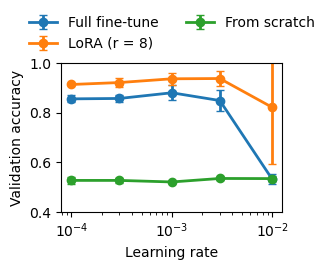

In [6]:
TUNE_SEEDS = SEEDS[:3]
TUNED = {"full": ("Full fine-tune", full_finetune),
         "lora": (f"LoRA (r = {DEFAULT_RANK})", lora(DEFAULT_RANK)),
         "scratch": ("From scratch", kryptonet)}
lr_results = {key: {lr: run(make, lr, seeds=TUNE_SEEDS) for lr in LR_GRID} for key, (_, make) in TUNED.items()}
for key, by_lr in lr_results.items():
    LR[key] = max(LR_GRID, key=lambda lr: summary(by_lr[lr], "val")[0])
    print(f"{TUNED[key][0]:<16} " + "  ".join(f"{lr:g}: {summary(by_lr[lr], 'val')[0]:.3f}" for lr in LR_GRID)
          + f"   chosen {LR[key]:g}")

fig, ax = plt.subplots(figsize=(3.25, 2.8))
for key, (name, _) in TUNED.items():
    means, stds = zip(*(summary(lr_results[key][lr], "val") for lr in LR_GRID))
    ax.errorbar(LR_GRID, means, yerr=stds, marker="o", lw=2, capsize=3, label=name)
ax.set_xscale("log")
ax.set_xlabel("Learning rate"); ax.set_ylabel("Validation accuracy"); ax.set_ylim(0.4, 1.0)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
fig.tight_layout(); save(fig, "lora_learning_rate"); plt.show()

## Experiment 1: Adaptation Methods

All methods use the same test split, seeds and training loop.

Zero-shot        test 0.481 ± 0.000   val   -     trainable       0      0.0 s per run
Linear probe     test 0.501 ± 0.014   val 0.531   trainable     513      1.5 s per run
MLP probe        test 0.496 ± 0.014   val 0.531   trainable 263,169      3.3 s per run
Full fine-tune   test 0.873 ± 0.026   val 0.872   trainable 809,473      5.6 s per run
LoRA (r = 8)     test 0.935 ± 0.015   val 0.943   trainable  28,992      4.6 s per run
From scratch     test 0.496 ± 0.014   val 0.530   trainable 809,473      4.4 s per run


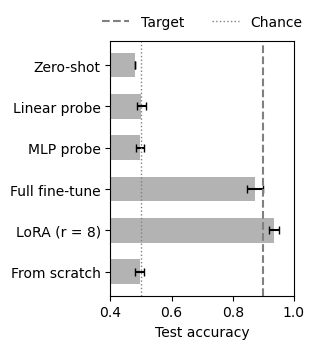

In [7]:
METHODS = {
    "Zero-shot": (frozen, None),
    "Linear probe": (linear_probe, LR["probe"]),
    "MLP probe": (mlp_probe, LR["mlp_probe"]),
    "Full fine-tune": (full_finetune, LR["full"]),
    f"LoRA (r = {DEFAULT_RANK})": (lora(DEFAULT_RANK), LR["lora"]),
    "From scratch": (kryptonet, LR["scratch"]),
}
results = {name: run(make, lr) for name, (make, lr) in METHODS.items()}
table(results)
fig = bars(results); save(fig, "lora_methods"); plt.show()

## Experiment 2: Rank

LoRA on $W_1, \dots, W_4$ with the rank $r$ varied and $\alpha$ fixed, so the update is scaled by $\alpha / r$.

r = 1            test 0.935 ± 0.018   val 0.942   trainable   3,624      4.3 s per run
r = 2            test 0.934 ± 0.019   val 0.939   trainable   7,248      5.4 s per run
r = 4            test 0.945 ± 0.004   val 0.952   trainable  14,496      3.8 s per run
r = 8            test 0.935 ± 0.015   val 0.943   trainable  28,992      4.6 s per run
r = 16           test 0.946 ± 0.003   val 0.953   trainable  57,984      4.3 s per run
r = 32           test 0.940 ± 0.009   val 0.951   trainable 115,968      4.9 s per run


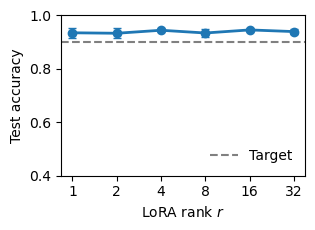

In [8]:
RANKS = (1, 2, 4, 8, 16, 32)
rank_results = {r: run(lora(r), LR["lora"]) for r in RANKS}
table({f"r = {r}": rows for r, rows in rank_results.items()})

fig, ax = plt.subplots(figsize=(3.25, 2.4))
means, stds = zip(*(summary(rank_results[r]) for r in RANKS))
ax.errorbar(range(len(RANKS)), means, yerr=stds, marker="o", lw=2, capsize=3)
ax.axhline(TARGET, color="gray", ls="--", lw=1.5, label="Target")
ax.set_xticks(range(len(RANKS))); ax.set_xticklabels([str(r) for r in RANKS])
ax.set_xlabel("LoRA rank $r$"); ax.set_ylabel("Test accuracy"); ax.set_ylim(0.4, 1.0)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); save(fig, "lora_rank"); plt.show()

## Experiment 3: Which Layers to Adapt

W1               test 0.952 ± 0.002   val 0.958   trainable   4,416      2.5 s per run
W4               test 0.494 ± 0.015   val 0.536   trainable   8,192      3.0 s per run
W2-W4            test 0.919 ± 0.014   val 0.932   trainable  24,576      5.1 s per run
W1-W4            test 0.935 ± 0.015   val 0.943   trainable  28,992      4.7 s per run


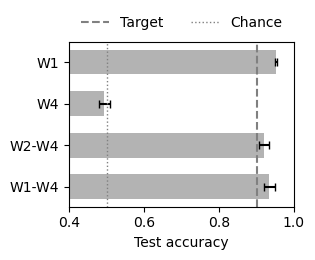

In [9]:
LAYER_SETS = {"W1": (1,), "W4": (4,), "W2-W4": (2, 3, 4), "W1-W4": (1, 2, 3, 4)}
layer_results = {name: run(lora(DEFAULT_RANK, layers), LR["lora"]) for name, layers in LAYER_SETS.items()}
table(layer_results)
fig = bars(layer_results); save(fig, "lora_layers"); plt.show()

## Experiment 4: Amount of Adaptation Data

Each method is trained on random subsets of the 3,200 pool rows (20% of each subset is used for early stopping) and evaluated on the same test set.

In [10]:
SIZES = (250, 500, 1000, 2000, 3200)
CURVES = {f"LoRA (r = {DEFAULT_RANK})": (lora(DEFAULT_RANK), LR["lora"]),
          "Full fine-tune": (full_finetune, LR["full"]), "From scratch": (kryptonet, LR["scratch"])}
size_results = {name: {n: run(make, lr, n) for n in SIZES} for name, (make, lr) in CURVES.items()}
for name, by_size in size_results.items():
    print(name, "  ".join(f"{n}: {summary(rows)[0]:.3f}" for n, rows in by_size.items()))

LoRA (r = 8) 250: 0.496  500: 0.577  1000: 0.743  2000: 0.919  3200: 0.935
Full fine-tune 250: 0.493  500: 0.527  1000: 0.590  2000: 0.758  3200: 0.873
From scratch 250: 0.513  500: 0.498  1000: 0.504  2000: 0.512  3200: 0.496


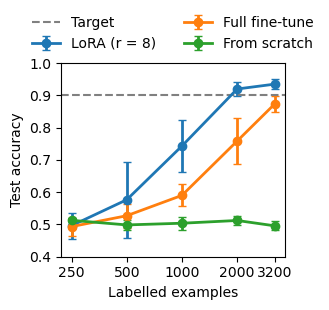

In [11]:
fig, ax = plt.subplots(figsize=(3.25, 3.2))
for name, by_size in size_results.items():
    means, stds = zip(*(summary(by_size[n]) for n in SIZES))
    ax.errorbar(SIZES, means, yerr=stds, marker="o", lw=2, capsize=3, label=name)
ax.axhline(TARGET, color="gray", ls="--", lw=1.5, label="Target")
ax.set_xscale("log"); ax.set_xticks(SIZES); ax.set_xticklabels([str(n) for n in SIZES])
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_xlabel("Labelled examples"); ax.set_ylabel("Test accuracy"); ax.set_ylim(0.4, 1.0)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
fig.tight_layout(); save(fig, "lora_data"); plt.show()

## Experiment 5: Cost of One Training Step

Measured time for one forward and one backward pass of a single $512 \times 512$ layer over a batch of $N$ inputs, for LoRA evaluated in the factored order $(xA^\top)B^\top$ and in the merged order $x(W + \frac{\alpha}{r}BA)^\top$, relative to full fine-tuning of the same layer. The input requires a gradient, as it would for a hidden layer, and the timing runs on one thread so that time tracks the operation count more closely.

The predicted ratios (dashed) come from `ops_full`, `ops_lora_factored` and `ops_lora_merged`, the operation counts derived in the report; the cell after the plot checks them exactly against the operations PyTorch performs.

N =   16  Full fine-tune:    0.45 ms  LoRA r = 8, factored:    0.49 ms  LoRA r = 8, merged:    0.83 ms
N =   64  Full fine-tune:    1.34 ms  LoRA r = 8, factored:    1.08 ms  LoRA r = 8, merged:    1.72 ms
N =  256  Full fine-tune:    5.02 ms  LoRA r = 8, factored:    3.97 ms  LoRA r = 8, merged:    5.48 ms
N = 1024  Full fine-tune:   20.54 ms  LoRA r = 8, factored:   15.94 ms  LoRA r = 8, merged:   20.10 ms
N = 4096  Full fine-tune:   79.29 ms  LoRA r = 8, factored:   64.74 ms  LoRA r = 8, merged:   77.78 ms


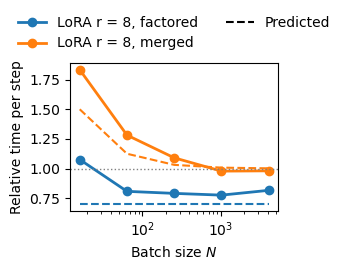

In [12]:
def ops_full(N, d_in, d_out):
    # forward W^T, weight gradient G^T X, input gradient G W
    return 3 * N * d_in * d_out


def ops_lora_factored(N, d_in, d_out, r):
    # frozen X W^T and G W, plus X A^T, U B^T, G^T U, G B, V^T X and V A
    return 2 * N * d_in * d_out + 3 * N * r * (d_in + d_out)


def ops_lora_merged(N, d_in, d_out, r):
    # form B A, forward X W'^T, gradient G^T X for W', input gradient G W', then (G^T X) A^T and B^T (G^T X)
    return 3 * N * d_in * d_out + 3 * r * d_in * d_out


def step_time(layer, N, d_in, reps=30):
    # Median seconds for one forward and backward pass over N inputs.
    x = torch.randn(N, d_in, requires_grad=True)
    times = []
    for _ in range(reps + 3):
        start = time.perf_counter()
        layer(x).sum().backward()
        times.append(time.perf_counter() - start)
        layer.zero_grad(); x.grad = None
    return float(np.median(times[3:]))


D, R = 512, DEFAULT_RANK
BATCHES = (16, 64, 256, 1024, 4096)
LAYERS = {"Full fine-tune": nn.Linear(D, D),
          f"LoRA r = {R}, factored": LoRALinear(nn.Linear(D, D), R, ALPHA),
          f"LoRA r = {R}, merged": LoRALinear(nn.Linear(D, D), R, ALPHA, merged=True)}
threads = torch.get_num_threads(); torch.set_num_threads(1)
timing = {name: [step_time(layer, N, D) for N in BATCHES] for name, layer in LAYERS.items()}
torch.set_num_threads(threads)

for i, N in enumerate(BATCHES):
    print(f"N = {N:>4}  " + "  ".join(f"{name}: {timing[name][i] * 1e3:7.2f} ms" for name in LAYERS))
fig, ax = plt.subplots(figsize=(3.25, 2.8))
full = np.array(timing["Full fine-tune"])
OPS = {f"LoRA r = {R}, factored": ops_lora_factored, f"LoRA r = {R}, merged": ops_lora_merged}
for name, ops in OPS.items():
    line, = ax.plot(BATCHES, np.array(timing[name]) / full, marker="o", lw=2, label=name)
    ax.plot(BATCHES, [ops(N, D, D, R) / ops_full(N, D, D) for N in BATCHES], "--", color=line.get_color(), lw=1.5)
ax.plot([], [], "k--", lw=1.5, label="Predicted")
ax.axhline(1, color="gray", ls=":", lw=1)
ax.set_xscale("log")
ax.set_xlabel("Batch size $N$"); ax.set_ylabel("Relative time per step")
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
fig.tight_layout(); save(fig, "lora_step_cost"); plt.show()

PyTorch's `FlopCounterMode` counts the matrix-product operations autograd actually performs in one forward and backward pass. It counts $2nmk$ per product (a multiply and an add), so its total is halved here to match the $nmk$ convention. Comparing it with `ops_full`, `ops_lora_factored` and `ops_lora_merged` for the shapes of $W_1$ and of $W_2, \dots, W_4$ checks the derivation exactly, without any timing noise. The table below it shows that the merged order costs more than full fine-tuning at every batch size, while the factored order costs a fixed fraction of it.

In [13]:
def counted_ops(layer, N, d_in):
    # Matrix-product operations PyTorch performs in one forward and backward pass, halved from its 2nmk count.
    x = torch.randn(N, d_in, requires_grad=True)
    with FlopCounterMode(display=False) as counter:
        layer(x).sum().backward()
    return counter.get_total_flops() // 2


checked = 0
for d_in, d_out in ((40, 512), (512, 512)):  # the shapes of W1 and of W2-W4
    for r in (1, 8, 32):
        for N in BATCHES:
            assert counted_ops(nn.Linear(d_in, d_out), N, d_in) == ops_full(N, d_in, d_out)
            assert (counted_ops(LoRALinear(nn.Linear(d_in, d_out), r, ALPHA), N, d_in)
                    == ops_lora_factored(N, d_in, d_out, r))
            assert (counted_ops(LoRALinear(nn.Linear(d_in, d_out), r, ALPHA, merged=True), N, d_in)
                    == ops_lora_merged(N, d_in, d_out, r))
            checked += 1
print(f"ops_full, ops_lora_factored and ops_lora_merged match PyTorch's count in all {checked} cases")

for N in BATCHES:
    full, factored, merged = (counted_ops(layer, N, D) for layer in LAYERS.values())
    print(f"N = {N:>4}  full {full:>13,}  LoRA factored {factored:>13,} ({factored / full:.3f})"
          f"  LoRA merged {merged:>13,} ({merged / full:.3f})")

ops_full, ops_lora_factored and ops_lora_merged match PyTorch's count in all 30 cases
N =   16  full    12,582,912  LoRA factored     8,781,824 (0.698)  LoRA merged    18,874,368 (1.500)
N =   64  full    50,331,648  LoRA factored    35,127,296 (0.698)  LoRA merged    56,623,104 (1.125)
N =  256  full   201,326,592  LoRA factored   140,509,184 (0.698)  LoRA merged   207,618,048 (1.031)
N = 1024  full   805,306,368  LoRA factored   562,036,736 (0.698)  LoRA merged   811,597,824 (1.008)
N = 4096  full 3,221,225,472  LoRA factored 2,248,146,944 (0.698)  LoRA merged 3,227,516,928 (1.002)


## Compute Used

Total training time and CPU energy across every training run above, for the environmental impact assessment. The energy is measured by CodeCarbon from the processor's own energy counters while each run trains (the whole package, so other programs should be closed). Every model runs on the CPU only, so no GPU energy is counted; RAM and screen are not measured, nor are the step-cost benchmark and the hidden-set refits. If the CPU counters cannot be read, CodeCarbon falls back to an estimate and no energy is reported.

In [14]:
# UK electricity consumed, including grid losses: 0.14396 kgCO2e/kWh for data year 2025 (DESNZ,
# 2026 Government GHG conversion factors for company reporting: Methodology paper, Table 9)
GRID_G_PER_KWH = 143.96

all_runs = [row for group in (results, rank_results, layer_results) for rows in group.values() for row in rows]
all_runs += [row for nested in (lr_results, size_results) for group in nested.values() for rows in group.values()
             for row in rows]
hours = sum(row["seconds"] for row in all_runs) / 3600
kwh = sum(row["cpu_kwh"] for row in all_runs)
print(f"{len(all_runs)} training runs, {hours:.2f} h of training in total")
for name, rows in results.items():
    print(f"  {name:<16} {np.mean([r['seconds'] for r in rows]):6.1f} s and"
          f" {np.mean([r['cpu_kwh'] for r in rows]) * 1000:6.3f} Wh per run")
if cpu_mode() in MEASURED:
    print(f"{kwh * 1000:.1f} Wh of CPU energy measured ({cpu_mode()}, whole package), an average of"
          f" {kwh * 1000 / hours:.0f} W, and {kwh * GRID_G_PER_KWH:.1f} g CO2e at {GRID_G_PER_KWH} g per kWh")
else:
    print(f"Energy not reported: CodeCarbon could not read the CPU's energy counters and fell back to"
          f" {cpu_mode()!r}, an estimate")

200 training runs, 0.23 h of training in total
  Zero-shot           0.0 s and  0.000 Wh per run
  Linear probe        1.5 s and  0.014 Wh per run
  MLP probe           3.3 s and  0.029 Wh per run
  Full fine-tune      5.6 s and  0.046 Wh per run
  LoRA (r = 8)        4.6 s and  0.041 Wh per run
  From scratch        4.4 s and  0.037 Wh per run
7.7 Wh of CPU energy measured (windows_emi, whole package), an average of 33 W, and 1.1 g CO2e at 143.96 g per kWh


## Hidden-Set Predictions

The configuration is chosen by mean validation accuracy over the rank sweep and the layer ablation, so the test set plays no part in the choice. The final predictor averages the logits of one model per seed, each trained on all 4,000 labelled rows with its own 20% early-stopping split.

In [15]:
candidates = {f"r = {r}, W1-W4": (lora(r), rows) for r, rows in rank_results.items()}
candidates.update({f"r = {DEFAULT_RANK}, {name}": (lora(DEFAULT_RANK, LAYER_SETS[name]), rows)
                   for name, rows in layer_results.items()})
best = max(candidates, key=lambda k: summary(candidates[k][1], "val")[0])
make_best, rows = candidates[best]
print(f"selected {best}: validation {summary(rows, 'val')[0]:.3f}, test {summary(rows)[0]:.3f} ± {summary(rows)[1]:.3f}")

models = []
for seed in SEEDS:
    torch.manual_seed(seed)
    models.append(fit(make_best(), X, y, LR["lora"], seed)[0])
with torch.no_grad():
    logits = torch.stack([m(torch.from_numpy(X_hidden)).squeeze(1) for m in models]).mean(0)
y_hidden = (logits > 0).long().numpy()
assert y_hidden.shape == (10_000,) and set(np.unique(y_hidden)) <= {0, 1}
print(f"fraction predicted positive on the hidden set: {y_hidden.mean():.3f}")
os.makedirs("../../hiddenlabels", exist_ok=True)
np.save("../../hiddenlabels/y_predicted_40_adapt.npy", y_hidden)

selected r = 8, W1: validation 0.958, test 0.952 ± 0.002
fraction predicted positive on the hidden set: 0.512
